# CsI(Tl)–SiPM：光电子统计、被动读出与 PID 带宽

日期：2026-10-29。接续 [带宽与噪声分解](codex_0001_csi_pid_bandwidth.ipynb)。
本轮开始前已提交并推送 [db3dcff3](https://github.com/laoshifei/SiPM/commit/db3dcff3e189cb4c73bde1db5af8e9cca6e68c76)；本笔记记录其后的改进。

上轮只改信号期相关噪声后，Co 的长短门带仍偏宽。正的附加噪声不能直接减去过大的原生统计方差。
本轮在同一原生 Geant4 工程内加入**共同被动信号电压传输系数**，扫描有效光电子统计规模，联合约束三个 PID 的协方差与短尺度起伏。
随后冻结参数，用 **32000 个新种子母衰变**重新完成核衰变、光学输运和原生数字化。

实测无逐事件粒子真值。Am 源的 α、γ 和衰变电子都保留，不能把源名称直接当成粒子标签。


In [1]:
from pathlib import Path
import json, sys
import numpy as np
from IPython.display import display, Markdown, Image
PROJECT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'simulation/main.cc').exists())
OUT=PROJECT/'simulation/results/pid_npe_20261029'
def read(p): return json.loads(Path(p).read_text())
def table(headers,rows):
    return '\n'.join(['|'+'|'.join(headers)+'|','|'+'|'.join(['---']*len(headers))+'|']+['|'+'|'.join(map(str,r))+'|' for r in rows])
selection=read(OUT/'selection.json'); protocol=read(OUT/'validation/protocol.json')
report=read(OUT/'validation/assessment.json'); decision=read(OUT/'decision.json')
methods=report['methods']; labels=['长短门比','负平均时间','冻结 PCA']
print('Project:',PROJECT)
print('Python / NumPy:',sys.version.split()[0],np.__version__)
display(Markdown(decision['summary_zh']))

Project: /media/sf_works/SiPM
Python / NumPy: 3.13.5 2.5.4


提高有效光电子统计并加入共同的被动电压传输系数后，Co 过宽的问题明显减轻，run18 的三种 PID 带宽比接近1；run12 后段平均时间带仍偏窄。平均 ADC 波形保持约1%的峰值归一化均方根误差。本轮属于有条件改善，尚未实现所有采集段、所有判别量的中心和带宽同时一致。

## 1. 为什么平均波形相同，PID 带宽仍可不同

在线性读出近似下，平均电压由光电子数、单雪崩电荷以及电流到 ADC 的传输共同决定。
固定形状、独立计数的简化模型给出相对计数起伏约为 $N_{pe}^{-1/2}$；实际 PID 是有共同积分门、对齐及筛选的比值，不能直接把此式当成完整带宽公式。

本轮检验的模型族是增加有效光电子规模 $s$，同时取共同电压传输系数 $\eta=1/s$，近似保持平均 ADC 幅度：

$$V_{\rm ADC}(t)=\eta\,V_{\rm SiPM,readout}(t)+n_B(t)+n_S(t).$$

`ReadoutResponse` 在原生 C++ 中对无噪信号电压施加一次固定传输，随后才添加电子学噪声与信号相关残差。
它不读取源名称或 run 标签；两源和三个状态共用同一个 $\eta$。
SiPM 物理增益、名义50 Ω、电流和雪崩电荷记账保持；输出电压衰减不能当成物理雪崩电荷减半。
`signal_transmission` 省略时为1；有效范围 `(0,1]`。

这个参数表示尚未确定的求和/耦合网络的有效电压传输，**没有证据证明实际电路恰好损失一半电压**。
各 run 的相关残差仍分别由训练数据约束，不代表核素有不同 SiPM 参数。

## 2. 训练扫描与最终物理配置

只使用冻结的前60%实验波形。候选 $s=1,1.5,2,3$ 先重放此前 Geant4 光学历史，用 PDE thinning 提议不同统计规模；
这些数值扫描的 PDE 为0.3/0.45/0.6/0.9，**后几个值只是计算代理，不能当作 S13361 的效率测量**。
每个候选联合拟合三个 PID 的3×3协方差及50/102/202 ns起伏均值，附加频谱功率非负。
采集状态、信号相依方差与前触发模型均保留，具体脚本和参数哈希归档。

选择准则为 run3 与 run12 训练残差分数之和最小。run18 在选定共同规模后只拟合自己的前60%残差状态。
分数不是卡方或似然；协方差用有限样本，线性化在固定 native anchor 下进行，最终必须检查真实 ADC。

选中的 $s=2$ 在完整验证中**恢复名义 PDE=0.3，把 Geant4 光产额乘2**，并保留 $\eta=0.5$。
3倍候选的分数也接近，因此不能从这些数据单独确定本征光产额、PDE、有效收光量或电路传输。


|共同规模|联合训练分数|Co 分数|Am 分数|
|---|---|---|---|
|1.0|23.7047|23.5333|0.1714|
|1.5|4.2756|4.0539|0.2217|
|2.0|1.3281|1.0717|0.2564|
|3.0|1.5047|1.2288|0.2759|

|配置项|最终验证值|
|---|---|
|最终光产额（条件参数）|35180.391310 ph/MeV|
|名义 PDE|0.3|
|共同电压传输|0.5|
|SiPM 物理增益（保持名义值）|1700000.0|
|名义负载|50.0 Ω|
|低通时间常数|126.815632 ns|

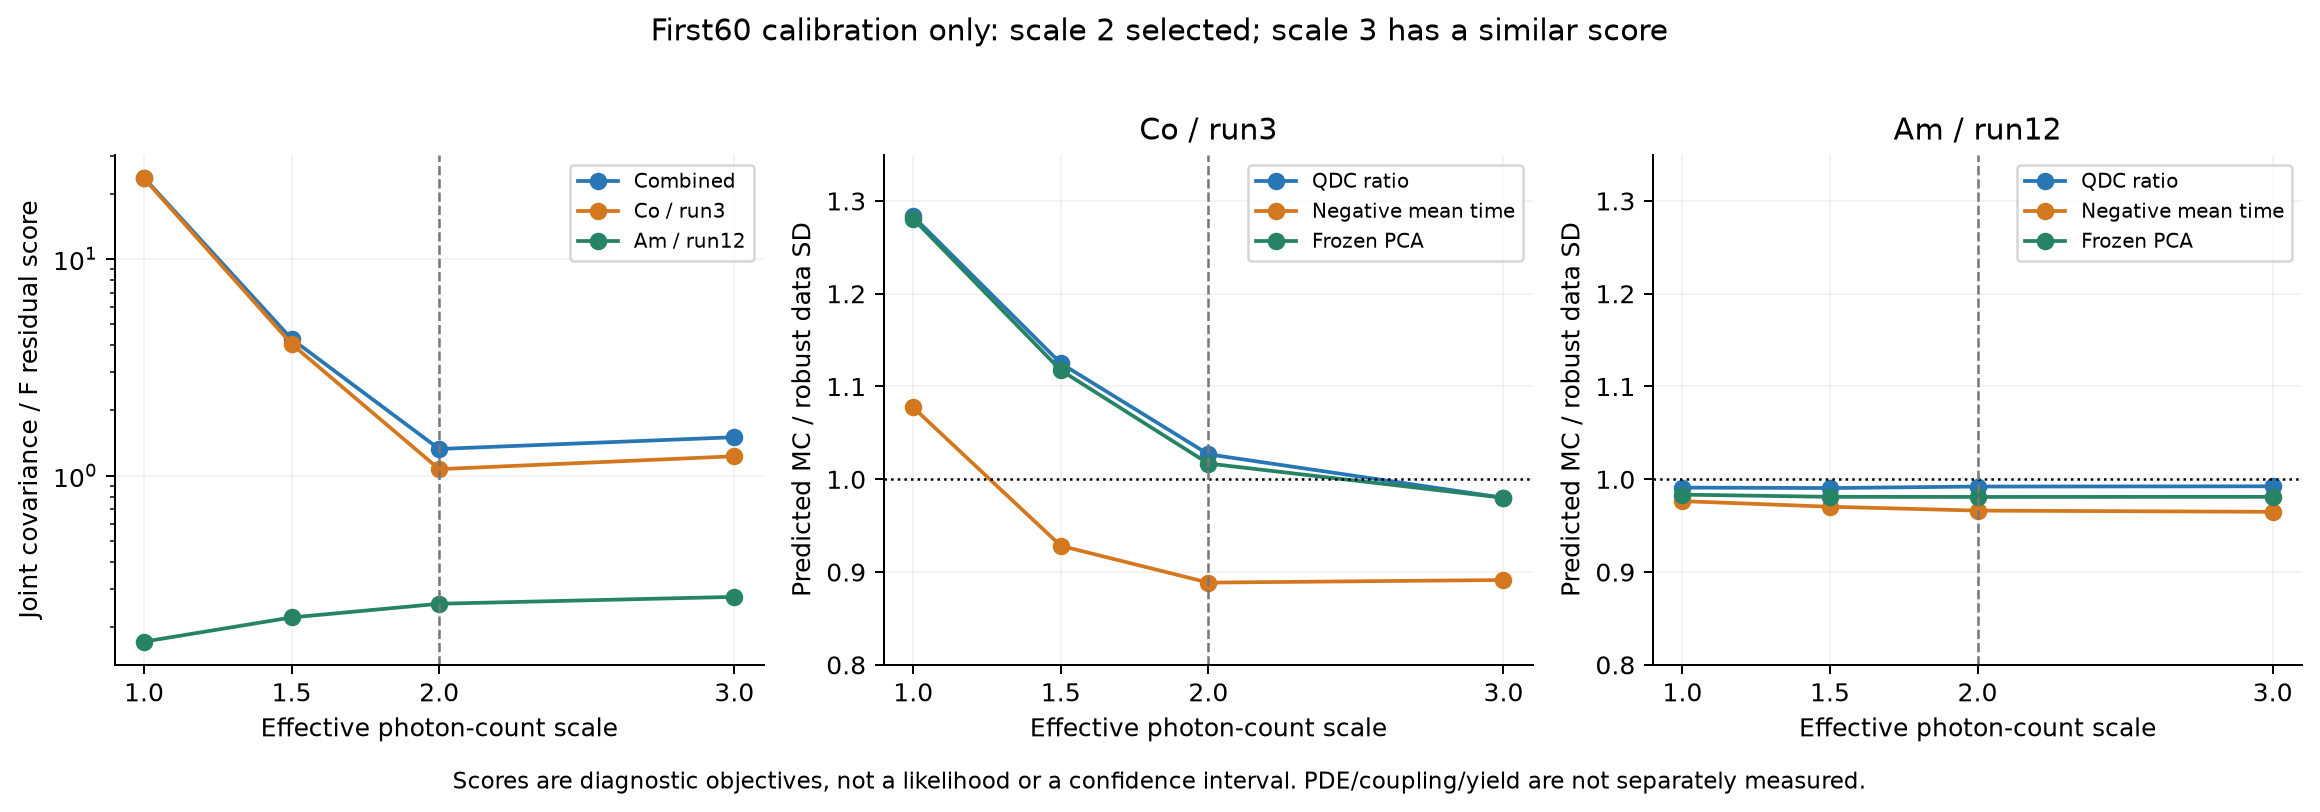

In [2]:
rows=[]
for r in selection['grid']:
    rows.append([r['scale'],f"{r['joint_score']:.4f}",f"{r['Co_score']:.4f}",f"{r['Am_score']:.4f}"])
display(Markdown(table(['共同规模','联合训练分数','Co 分数','Am 分数'],rows)))
c=read(PROJECT/protocol['entries']['run12_Am241']['config'])
rows=[['最终光产额（条件参数）',f"{c['optical']['yield_photons_per_MeV']:.6f} ph/MeV"],
      ['名义 PDE',c['sipm']['sensor']['constant_pde']],['共同电压传输',c['readout_response']['signal_transmission']],
      ['SiPM 物理增益（保持名义值）',c['sipm']['sensor']['gain_electrons']],
      ['名义负载',f"{c['sipm']['readout']['transimpedance_ohm']} Ω"],
      ['低通时间常数',f"{c['sipm']['readout']['lowpass_ns']:.6f} ns"]]
display(Markdown(table(['配置项','最终验证值'],rows)))
display(Image(filename=str(OUT/'figures/npe_training_profile.png')))

## 3. 新完整输运：冻结参数后的检查

Co：8000个母衰变，seed=301029203；Am：24000个母衰变，seed=301029212。
同源光学历史另重放到 run18 Am 和共同 run12 Co 响应；重放不增加独立母事件。
此前用于扫描的8000 Co / 48000 Am 历史在本轮已成为校准支撑，不能再称本轮独立验证。

原始 ADC 执行质量、前触发、幅度≥200、t10≥384样本、完整3 µs积分和共同Q范围筛选。
模拟不按 PID 分数选事件；实验带宽诊断沿用已冻结的主带界线0.4（Co高侧、Am低侧），它不是实验真值。
在6个固定Q箱中，仅按预先支持的箱等权比较，避免混合不同带中心后误算带宽。

下表的带宽比是各支持箱 IQR 均方根的 MC/实验比值，理想值1。
95%区间使用512次整母事件模拟自举与实验原始索引64事件块自举；固定参数，不包含拟合与模型不确定度。
后40%数据此前已经探索，属于内部检查；本轮没有据此再次拟合。
旧噪声候选与新候选的完整输运种子不同，前后不是逐母事件配对对照。


|run|实验段|方法|前轮噪声候选|本轮MC/实验|本轮95%区间|
|---|---|---|---|---|---|
|3|first60|长短门比|1.336|1.063|[0.874, 1.242]|
|3|first60|负平均时间|1.052|0.948|[0.790, 1.099]|
|3|first60|冻结 PCA|1.251|1.041|[0.865, 1.191]|
|3|middle20|长短门比|1.443|1.148|[0.856, 1.375]|
|3|middle20|负平均时间|1.244|1.121|[0.844, 1.332]|
|3|middle20|冻结 PCA|1.408|1.171|[0.823, 1.451]|
|3|last20|长短门比|1.468|1.168|[0.868, 1.344]|
|3|last20|负平均时间|1.059|0.954|[0.799, 1.157]|
|3|last20|冻结 PCA|1.245|1.036|[0.828, 1.253]|
|12|first60|长短门比|0.939|0.956|[0.831, 1.218]|
|12|first60|负平均时间|0.891|0.964|[0.782, 1.134]|
|12|first60|冻结 PCA|0.903|0.942|[0.802, 1.249]|
|12|middle20|长短门比|0.983|1.000|[0.805, 1.314]|
|12|middle20|负平均时间|0.748|0.809|[0.638, 0.990]|
|12|middle20|冻结 PCA|0.933|0.973|[0.784, 1.349]|
|12|last20|长短门比|0.881|0.897|[0.725, 1.150]|
|12|last20|负平均时间|0.760|0.822|[0.662, 0.994]|
|12|last20|冻结 PCA|0.823|0.858|[0.720, 1.152]|
|18|first60|长短门比|0.902|0.969|[0.835, 1.217]|
|18|first60|负平均时间|0.894|0.959|[0.804, 1.105]|
|18|first60|冻结 PCA|0.891|1.046|[0.867, 1.274]|
|18|middle20|长短门比|0.888|0.954|[0.821, 1.182]|
|18|middle20|负平均时间|0.901|0.967|[0.798, 1.100]|
|18|middle20|冻结 PCA|0.912|1.071|[0.864, 1.274]|
|18|last20|长短门比|0.882|0.948|[0.823, 1.196]|
|18|last20|负平均时间|0.925|0.993|[0.809, 1.123]|
|18|last20|冻结 PCA|0.926|1.087|[0.875, 1.305]|

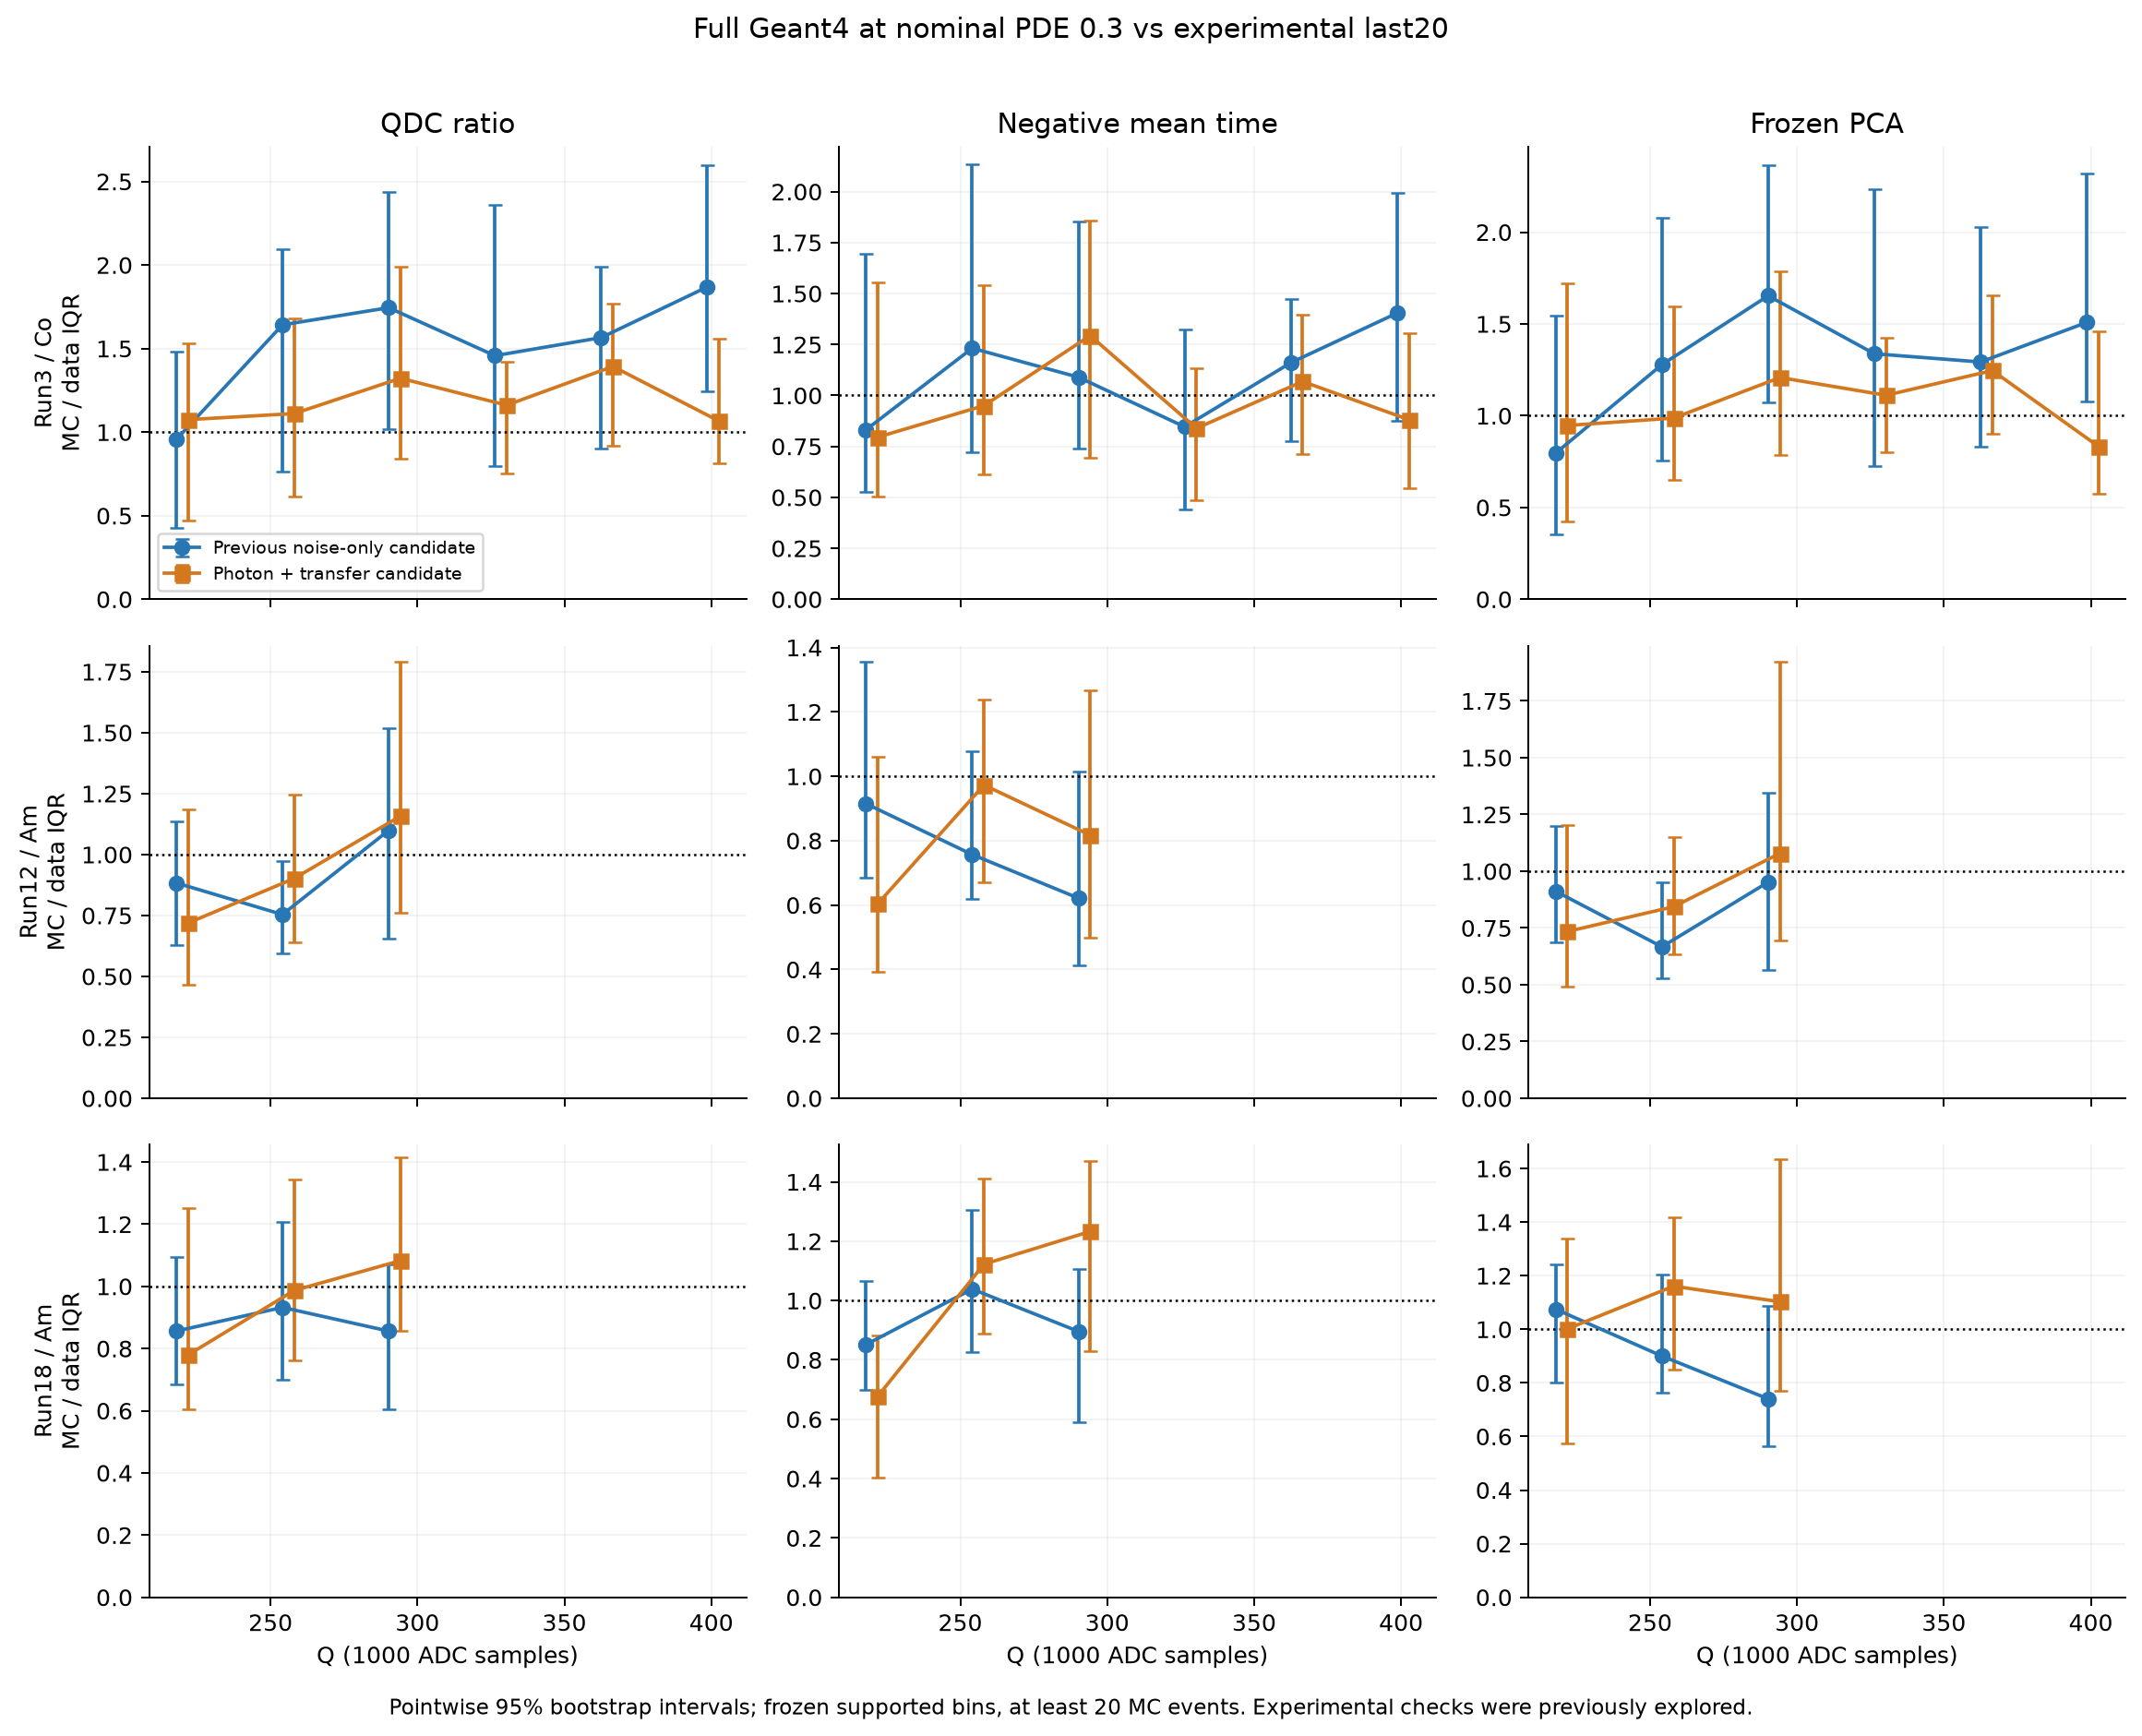

In [3]:
rows=[]
for run in [3,12,18]:
    for seg in ['first60','middle20','last20']:
        r=report['checks'][f'run{run}_{seg}']
        for j,label in enumerate(labels):
            lo,hi=r['IQR_ratio_CI95'][j]['estimate95']
            rows.append([run,seg,label,f"{r['previous_noise_only_IQR_ratio'][j]:.3f}",
                f"{r['IQR_ratio'][j]:.3f}",f'[{lo:.3f}, {hi:.3f}]'])
display(Markdown(table(['run','实验段','方法','前轮噪声候选','本轮MC/实验','本轮95%区间'],rows)))
display(Image(filename=str(OUT/'figures/npe_bandwidth_validation.png')))

## 4. 带宽改进是否破坏了平均波形

下图是相同支持Q箱等权的平均 ADC 波形，扣除基线并按 t10 对齐，**没有再按峰值或面积缩放幅度**。
波形 NRMSE 在 −40至3000 ns区间计算，以实验均波形峰值归一化；不等价于每个采样点都在1%内。
峰值比与短尺度起伏 F 同时报出。F 为同一局部去趋势/盒滤定义下的超额方差与平均信号之比。
这些条件检查不能证明全能谱、全部单条波形或实验外部条件已经一致。


|run|段|共同Q内MC数|平均ADC NRMSE/峰|MC/实测峰值|F50 / F102 / F202 比值|
|---|---|---|---|---|---|
|3|first60|280|0.96%|1.0248|1.019, 1.033, 1.005|
|3|last20|280|0.96%|1.0262|1.059, 1.072, 1.042|
|12|first60|206|1.13%|1.0250|1.030, 1.017, 1.026|
|12|last20|206|1.17%|1.0134|1.065, 1.037, 1.042|
|18|first60|208|1.02%|1.0162|1.057, 1.010, 1.013|
|18|last20|208|0.96%|1.0091|1.053, 1.005, 1.010|

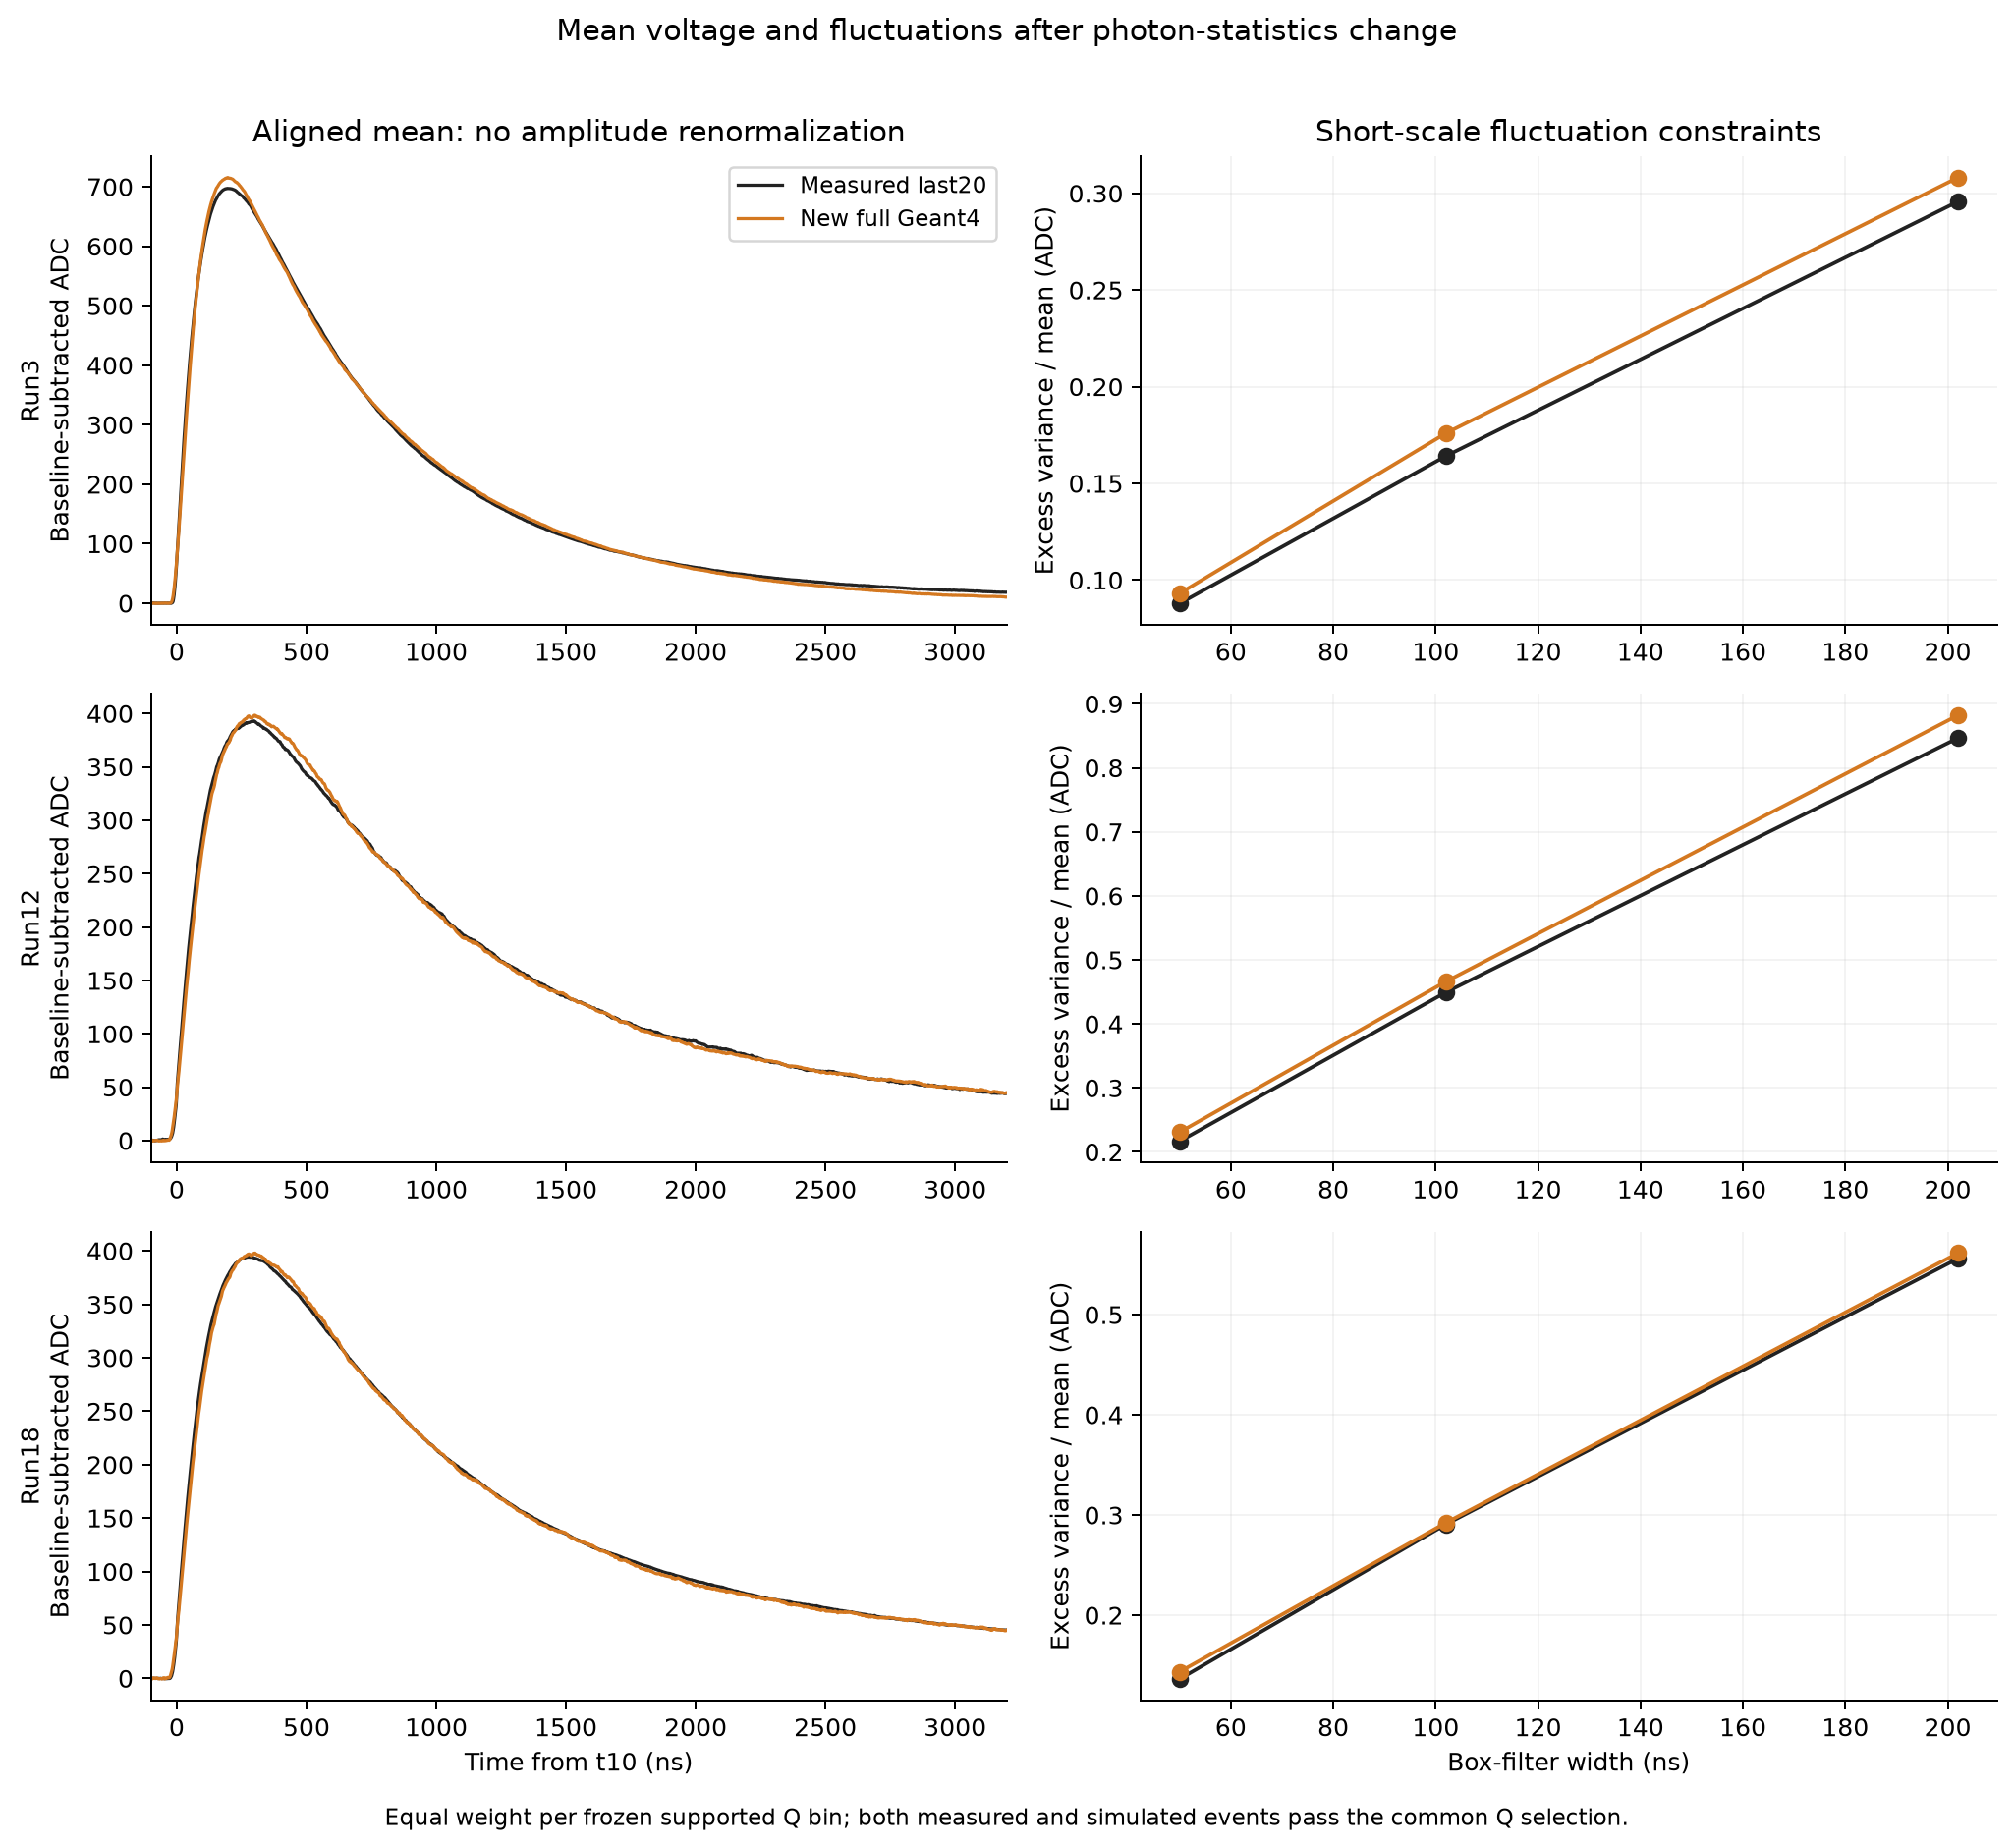

In [4]:
rows=[]
for run in [3,12,18]:
    for seg in ['first60','last20']:
        r=report['checks'][f'run{run}_{seg}']
        rows.append([run,seg,r['n_MC'],f"{100*r['mean_ADC_normalized_RMSE']:.2f}%",
          f"{r['mean_ADC_peak_ratio']:.4f}",', '.join(f'{v:.3f}' for v in r['F_ratio'])])
display(Markdown(table(['run','段','共同Q内MC数','平均ADC NRMSE/峰','MC/实测峰值','F50 / F102 / F202 比值'],rows)))
display(Image(filename=str(OUT/'figures/npe_waveform_validation.png')))

## 5. 仍未闭合的中心与采集状态

带宽比接近1并不保证带中心相同。下面用各Q箱的中位数差除以实验 IQR，再等权取均值；同时保存 RMS 中位数差。
Co 的平均时间中心仍有约0.79个实验 IQR 的偏移，微小尾部差异仍会影响带中心。

run12 的基线 RMS 中位数从前段约3.17 ADC升到最后段5.68 ADC，而前段状态模拟维持约3.17 ADC。
这是实测采集状态变化的证据，尚不能定量认定它解释了全部剩余 PID 带宽差异。
后续应利用已有触发前数据单独建模噪声状态，并分开噪声估计事件与 PID 检查事件，而不是用最后20%的 PID 带宽反调本轮参数。


|run|段|实测基线RMS|模拟基线RMS|三个PID的中心差/实测IQR|
|---|---|---|---|---|
|3|first60|3.353|3.350|0.213, 0.750, 0.300|
|3|middle20|3.333|3.350|0.323, 1.044, 0.406|
|3|last20|3.317|3.350|0.236, 0.786, 0.299|
|12|first60|3.167|3.174|0.060, 0.151, 0.072|
|12|middle20|4.415|3.174|-0.059, 0.104, 0.046|
|12|last20|5.677|3.174|-0.075, 0.062, -0.003|
|18|first60|4.965|4.894|0.078, 0.106, 0.027|
|18|middle20|4.986|4.894|-0.023, 0.104, -0.020|
|18|last20|4.950|4.894|0.007, 0.102, -0.017|

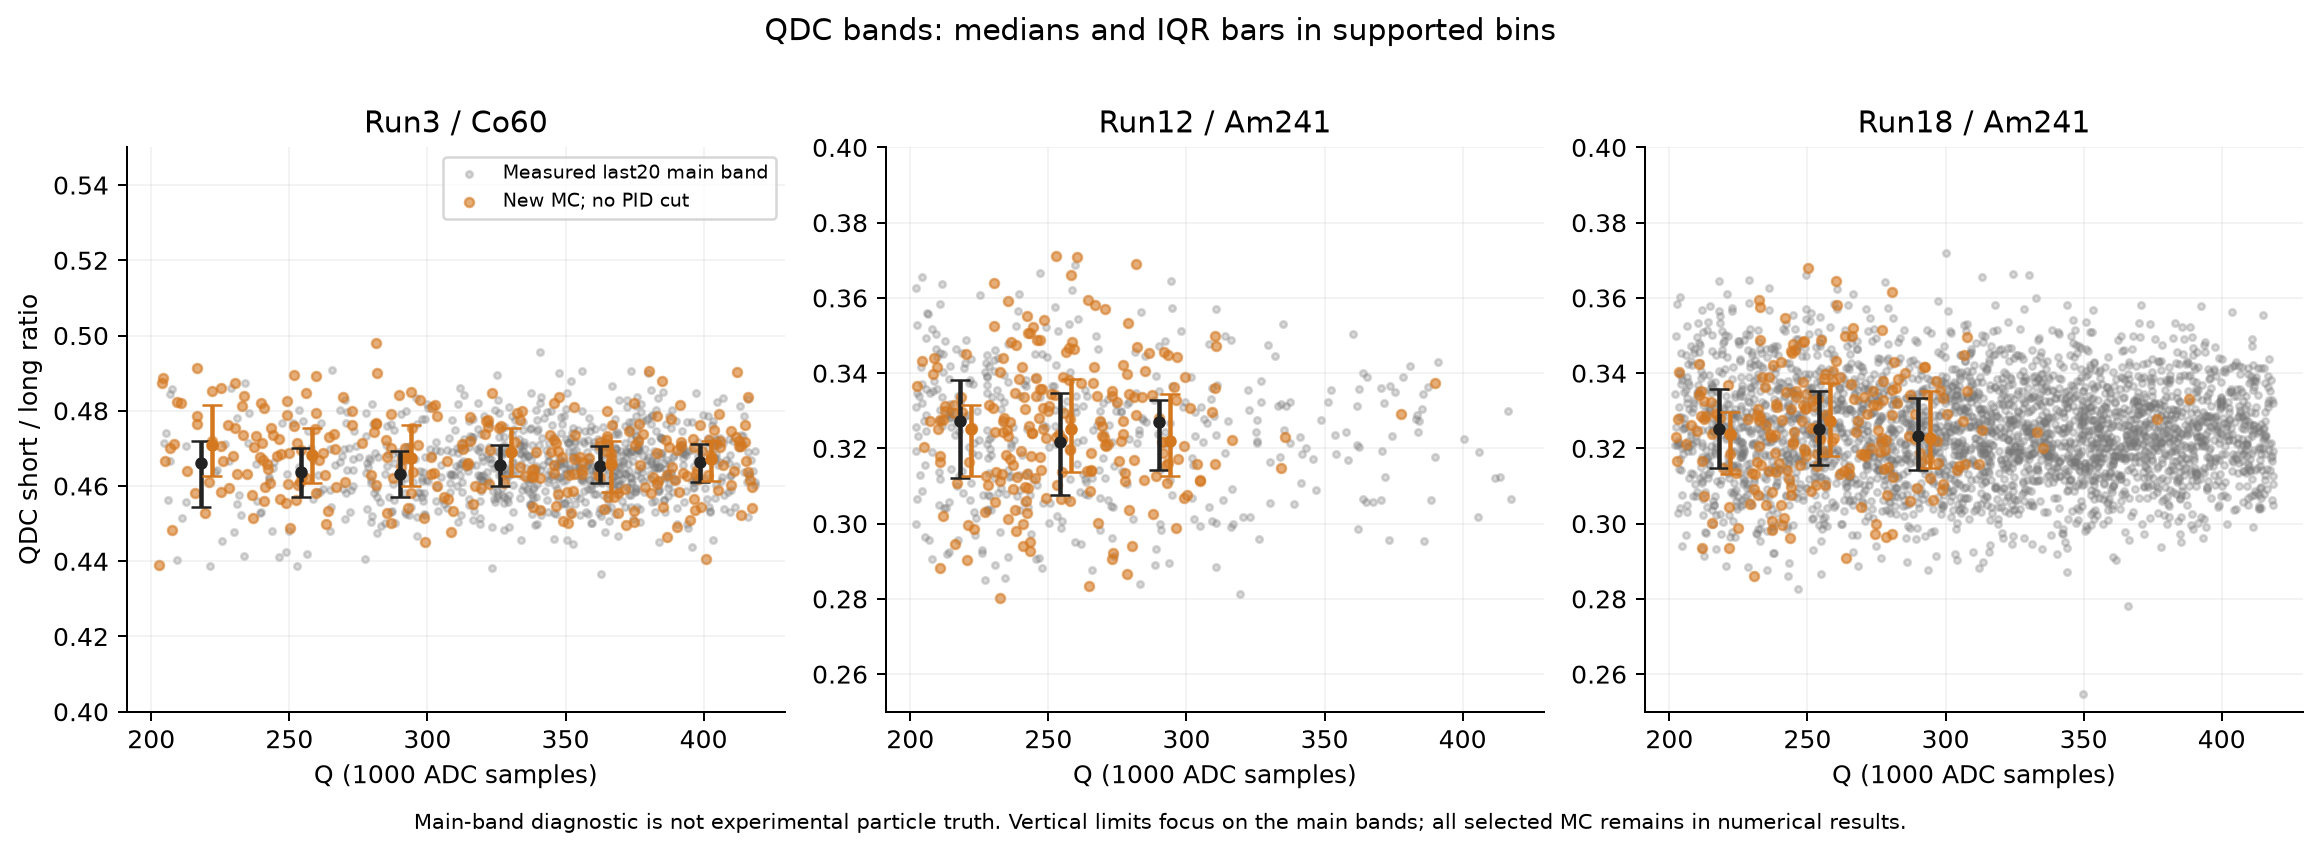

- run12 最后20%的平均时间带宽比为0.822，固定参数自举95%区间约[0.662,0.994]；这不是多重比较校正后的显著性结论。
- Co 平均时间带中心仍有约0.79个实验IQR的偏移；平均波形NRMSE约1%并不保证所有积分矩都吻合。
- run12 实验基线RMS中位数从训练段3.17 ADC上升到最后段5.68 ADC，当前训练态模拟约3.17 ADC。状态漂移已被观测到，但对PID残差的因果贡献尚未单独确定。
- 新MC样本的逐Q箱区间仍较宽；幅度和波形一致性只在当前共同Q区间及预先支持的箱内评价。
- 信号相关残差仍是经验采集状态，不能唯一认定为SiPM噪声、发光本征涨落或事件形状变化。

In [5]:
rows=[]
for run in [3,12,18]:
    for seg in ['first60','middle20','last20']:
        r=report['checks'][f'run{run}_{seg}']
        rows.append([run,seg,f"{r['baseline_RMS_median_data']:.3f}",f"{r['baseline_RMS_median_MC']:.3f}",
             ', '.join(f'{x:.3f}' for x in r['median_shift_in_data_IQR'])])
display(Markdown(table(['run','段','实测基线RMS','模拟基线RMS','三个PID的中心差/实测IQR'],rows)))
display(Image(filename=str(OUT/'figures/npe_QDC_bands.png')))
display(Markdown('\n'.join('- '+s for s in decision['unresolved_zh'])))

## 6. 同一读出状态下的 PID

两源使用完全相同的 run12 SiPM、被动响应、基线电子学和信号残差配置；几何沿用各源此前的条件假设。
粒子标签仅来自 MC 的沉积能量祖先（≥90%主导），PCA和三个阈值固定于此前研究。
这里不重新优化阈值，也不把模拟效率称作实测 α 接受率或 γ 泄漏率。


In [6]:
rows=[]
for j,m in enumerate(methods):
    r=report['common_run12_PID'][m];op=r['operating'];a=op['alpha_acceptance'];g=op['gamma_leakage']
    rows.append([labels[j],f"{r['AUC']:.6f}",f"{a['passed']}/{a['total']}",f"{100*a['fraction']:.2f}%",
        f"{g['passed']}/{g['total']}",f"{100*g['one_sided95_upper']:.2f}%"])
display(Markdown(table(['方法','AUC','模拟α通过','模拟接受比例','模拟γ误入','γ泄漏单侧95%上限'],rows)))
display(Markdown(decision['interpretation_zh']))

|方法|AUC|模拟α通过|模拟接受比例|模拟γ误入|γ泄漏单侧95%上限|
|---|---|---|---|---|---|
|长短门比|1.000000|201/206|97.57%|0/277|1.08%|
|负平均时间|1.000000|195/206|94.66%|0/277|1.08%|
|冻结 PCA|1.000000|199/206|96.60%|0/277|1.08%|

带宽包含光子/雪崩统计与信号期相关起伏，不能只靠增加基线白噪声解释。有效光电子规模2倍、共同电压传输系数0.5是训练选出的候选；3倍方案训练分数接近，光产额、PDE、收光和电路传输仍无法单独确定。完整验证使用名义PDE=0.3及2倍光产额；扫描中较高PDE只是数值提案，不代表器件实测值。

## 7. 实现、校验和复现

原生实现仍为 `simulation/include/ReadoutResponse.hh` 与 `simulation/src/ReadoutResponse.cc`，其余必需 Geant4 类及 `include/`、`src/` 结构保留。
Python 仅做参数扫描、统计分析和归档，不能替代 Geant4 输运。
独立构建目录为 `simulation/build/npe_20261029`；旧二进制和旧冻结结果保留。

5项 CTest 与3项双源原生/重放集成检查通过；新增检查覆盖系数1的原路径、0.5的信号电压、物理电荷保持以及下游噪声。
两个新完整 ROOT 已逐事件检查衰变内容、粒子/光子祖先、有限波形和电荷守恒。
最终归档验证还独立重算 ADC→三个 PID、固定阈值统计、前轮输出哈希及笔记输出。

主要步骤：`prepare_npe_profile.py` → `run_npe_profiles.py` → `prepare_npe_validation.py` → 原生/重放命令
→ `extract_npe_profile.py` → `analyze_npe_validation.py` → `plot_npe_validation.py` / `summarize_npe_validation.py`。
`validation/protocol.json` 保存实际配置、种子、二进制哈希及命令。已冻结目录拒绝覆盖；复现需要新的输出目录。

```bash
OPENBLAS_NUM_THREADS=1 OMP_NUM_THREADS=1 /home/xc/software/jupyter/.venv/bin/python simulation/verify_npe_validation.py
```

冻结后 `record.json` 包含源码快照和产物哈希；CSV为 `simulation/results/pid_npe_20261029/validation_table.csv`。
原始 ROOT、NPZ和图片保存在本地结果目录，不应把 Git 提交当作包含全部大数据的备份。


In [7]:
rows=[]
for key in ['run3_Co60','run12_Am241']:
    e=protocol['entries'][key];r=read((PROJECT/e['path']).with_name('events_validation.json'))
    rows.append([r['source'],r['events'],r['deposited_events'],r['passed'],f"{r['max_relative_charge_balance_error']:.3g}"])
display(Markdown(table(['源','新母事件数','有沉积事件数','原生检查通过','最大相对电荷记账误差'],rows)))
assert '100% tests passed' in (OUT/'logs/ctest.log').read_text()
assert (OUT/'logs/replay_tests.log').read_text().rstrip().endswith('OK')
print('工程测试：5个CTest目标 + 3个双源集成测试通过。')
display(Markdown('后续可用已有数据推进的工作：\n\n'+'\n'.join('- '+s for s in decision['next_steps_zh'])))

工程测试：5个CTest目标 + 3个双源集成测试通过。


|源|新母事件数|有沉积事件数|原生检查通过|最大相对电荷记账误差|
|---|---|---|---|---|
|Co60|8000|811|True|1.76e-13|
|Am241|24000|400|True|4.96e-14|

后续可用已有数据推进的工作：

- 保留这套候选作为后续基线，用已有触发前样本建立按时间变化的噪声状态模型，并把用于估计噪声与用于检查PID的事件分开。
- 对Co平均时间中心偏移检查训练段波形尾部和对齐误差；只在训练段修改共同响应或发光形状，再冻结新的检查。
- 论文同时报告条件参数退化、带宽区间与未闭合残差；不能把MC的高AUC或零误判计数写成实测效率。